In [ ]:
import pandas as pd
import numpy as np
from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:

uploaded = files.upload()

input_file = list(uploaded.keys())[0]

print("Input file:", input_file)

df = pd.read_excel(input_file)

print("\nColumns in file:")
print(df.columns.tolist())

print("\nNumber of rows:", len(df))

Saving Maharashtra_36_Districts_PCA_CCI_Final_Ranking (1).xlsx to Maharashtra_36_Districts_PCA_CCI_Final_Ranking (1).xlsx
Input file: Maharashtra_36_Districts_PCA_CCI_Final_Ranking (1).xlsx

Columns in file:
['District', 'Month', 'Rainfall_Slope', 'Tmax_Slope', 'Tmin_Slope', 'DTR_Slope', 'Rainfall_Slope_Abs', 'Tmax_Slope_Abs', 'Tmin_Slope_Abs', 'DTR_Slope_Abs', 'Rainfall_Normalized', 'Tmax_Normalized', 'Tmin_Normalized', 'DTR_Normalized']

Number of rows: 432


In [ ]:
required_columns = [
    'District',
    'Month',
    'Rainfall_Slope',
    'Tmax_Slope',
    'Tmin_Slope',
    'DTR_Slope'
]

missing = [col for col in required_columns if col not in df.columns]

if missing:
    print("\nERROR: These columns are missing:")
    print(missing)
    raise ValueError("Please check your Excel column names.")

In [ ]:
data = df[required_columns].copy()

# Convert slopes to numeric
slope_columns = [
    'Rainfall_Slope',
    'Tmax_Slope',
    'Tmin_Slope',
    'DTR_Slope'
]

for col in slope_columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')


# Remove rows where required values are missing
data = data.dropna(subset=slope_columns)

print("\nRows after removing missing values:", len(data))


Rows after removing missing values: 432


In [ ]:
for col in slope_columns:
    data[col + '_Abs'] = data[col].abs()

In [ ]:
normalized_columns = []

for col in slope_columns:

    abs_col = col + '_Abs'
    norm_col = col.replace('_Slope', '_Normalized')

    minimum = data[abs_col].min()
    maximum = data[abs_col].max()

    if maximum == minimum:
        data[norm_col] = 0
    else:
        data[norm_col] = (
            (data[abs_col] - minimum)
            / (maximum - minimum)
        ) * 100

    normalized_columns.append(norm_col)


In [ ]:
district_scores = (
    data
    .groupby('District')[normalized_columns]
    .mean()
    .reset_index()
)

# Rename columns
district_scores = district_scores.rename(columns={
    'Rainfall_Normalized': 'Rainfall_Score',
    'Tmax_Normalized': 'Tmax_Score',
    'Tmin_Normalized': 'Tmin_Score',
    'DTR_Normalized': 'DTR_Score'
})

score_columns = [
    'Rainfall_Score',
    'Tmax_Score',
    'Tmin_Score',
    'DTR_Score'
]

print("\nDistrict score table:")
print(district_scores.head())

print("\nNumber of districts:", len(district_scores))


# ============================================================
# STEP 7: CHECK 36 DISTRICTS
# ============================================================

print("\nDistricts:")
print(sorted(district_scores['District'].unique()))

if len(district_scores) != 36:
    print("\nWARNING:")
    print("Expected 36 districts, but found:",
          len(district_scores))


# ============================================================
# STEP 8: STANDARDIZATION
# ============================================================
#
# PCA requires variables to be on a comparable scale.
#
# Z = (X - mean) / standard deviation
#
# ============================================================

X = district_scores[score_columns].copy()

scaler = StandardScaler()

X_standardized = scaler.fit_transform(X)

standardized_df = pd.DataFrame(
    X_standardized,
    columns=[
        'Rainfall_Z',
        'Tmax_Z',
        'Tmin_Z',
        'DTR_Z'
    ]
)

standardized_df.insert(
    0,
    'District',
    district_scores['District']
)


# ============================================================
# STEP 9: CORRELATION MATRIX
# ============================================================

correlation_matrix = pd.DataFrame(
    X_standardized,
    columns=score_columns
).corr()

print("\n==========================================")
print("CORRELATION MATRIX")
print("==========================================")

print(correlation_matrix.round(4))


# ============================================================
# STEP 10: PCA
# ============================================================

pca = PCA()

pca.fit(X_standardized)


# ============================================================
# STEP 11: EIGENVALUES
# ============================================================

eigenvalues = pca.explained_variance_

variance_explained = (
    pca.explained_variance_ratio_ * 100
)

cumulative_variance = np.cumsum(
    variance_explained
)

eigenvalue_table = pd.DataFrame({

    'Principal_Component': [
        'PC1',
        'PC2',
        'PC3',
        'PC4'
    ],

    'Eigenvalue': eigenvalues,

    'Variance_Explained_%':
        variance_explained,

    'Cumulative_Variance_%':
        cumulative_variance
})

print("\n==========================================")
print("EIGENVALUES")
print("==========================================")

print(eigenvalue_table.round(4))


# ============================================================
# STEP 12: EIGENVECTORS
# ============================================================

eigenvectors = pd.DataFrame(
    pca.components_.T,

    index=[
        'Rainfall',
        'Tmax',
        'Tmin',
        'DTR'
    ],

    columns=[
        'PC1',
        'PC2',
        'PC3',
        'PC4'
    ]
)

print("\n==========================================")
print("EIGENVECTORS")
print("==========================================")

print(eigenvectors.round(4))


# ============================================================
# STEP 13: PCA LOADINGS
# ============================================================
#
# Loading =
# Eigenvector × square root of eigenvalue
#
# ============================================================

loadings = (
    pca.components_.T
    * np.sqrt(pca.explained_variance_)
)

loading_table = pd.DataFrame(
    loadings,

    index=[
        'Rainfall',
        'Tmax',
        'Tmin',
        'DTR'
    ],

    columns=[
        'PC1',
        'PC2',
        'PC3',
        'PC4'
    ]
)

print("\n==========================================")
print("PCA LOADINGS")
print("==========================================")

print(loading_table.round(4))


# ============================================================
# STEP 14: PC1 LOADINGS
# ============================================================
#
# We use the magnitude of PC1 loadings to determine
# relative contribution to the PCA-based index.
#
# Absolute value is used because the sign of a PCA loading
# can change depending on the direction of the eigenvector.
#
# ============================================================

pc1_absolute_loadings = loading_table['PC1'].abs()

pca_weights = (
    pc1_absolute_loadings
    / pc1_absolute_loadings.sum()
)

weights_table = pd.DataFrame({

    'Variable': [
        'Rainfall',
        'Tmax',
        'Tmin',
        'DTR'
    ],

    'PC1_Loading':
        loading_table['PC1'].values,

    'Absolute_PC1_Loading':
        pc1_absolute_loadings.values,

    'PCA_Weight':
        pca_weights.values
})

print("\n==========================================")
print("PCA WEIGHTS")
print("==========================================")

print(weights_table.round(4))

print("\nSum of weights:",
      pca_weights.sum())


# ============================================================
# STEP 15: PCA SCORES
# ============================================================

pca_scores = pca.transform(X_standardized)

pca_scores_table = pd.DataFrame(
    pca_scores,

    columns=[
        'PC1_Score',
        'PC2_Score',
        'PC3_Score',
        'PC4_Score'
    ]
)

pca_scores_table.insert(
    0,
    'District',
    district_scores['District']
)


# ============================================================
# STEP 16: FINAL PCA-BASED CCI
# ============================================================
#
# CCI =
#
# Rainfall Score × Rainfall Weight
# +
# Tmax Score × Tmax Weight
# +
# Tmin Score × Tmin Weight
# +
# DTR Score × DTR Weight
#
# ============================================================

final_cci = (
    district_scores['Rainfall_Score']
    * pca_weights.iloc[0]

    +

    district_scores['Tmax_Score']
    * pca_weights.iloc[1]

    +

    district_scores['Tmin_Score']
    * pca_weights.iloc[2]

    +

    district_scores['DTR_Score']
    * pca_weights.iloc[3]
)


# ============================================================
# STEP 17: CREATE FINAL RANKING
# ============================================================

final_ranking = district_scores[
    ['District',
     'Rainfall_Score',
     'Tmax_Score',
     'Tmin_Score',
     'DTR_Score']
].copy()

final_ranking['PCA_CCI'] = final_cci

# Highest CCI = greater magnitude of climate change
final_ranking = final_ranking.sort_values(
    'PCA_CCI',
    ascending=False
).reset_index(drop=True)

# Rank
final_ranking.insert(
    0,
    'Rank',
    range(1, len(final_ranking) + 1)
)


# ============================================================
# STEP 18: ADD PCA WEIGHTS TO FINAL TABLE
# ============================================================

final_ranking['Rainfall_Weight'] = pca_weights.iloc[0]
final_ranking['Tmax_Weight'] = pca_weights.iloc[1]
final_ranking['Tmin_Weight'] = pca_weights.iloc[2]
final_ranking['DTR_Weight'] = pca_weights.iloc[3]


# ============================================================
# STEP 19: PRINT FINAL RANKING
# ============================================================

print("\n==========================================")
print("FINAL PCA-BASED CCI RANKING")
print("==========================================")

print(
    final_ranking[
        ['Rank', 'District', 'PCA_CCI']
    ].round(4).to_string(index=False)
)


# ============================================================
# STEP 20: SAVE EVERYTHING TO ONE EXCEL FILE
# ============================================================

output_file = (
    "Maharashtra_36_Districts_PCA_CCI_Final_Ranking.xlsx"
)

with pd.ExcelWriter(
    output_file,
    engine='openpyxl'
) as writer:

    # Original trend data
    data.to_excel(
        writer,
        sheet_name='Monthly_Trend_Data',
        index=False
    )

    # District-level normalized scores
    district_scores.to_excel(
        writer,
        sheet_name='District_Scores',
        index=False
    )

    # Standardized scores
    standardized_df.to_excel(
        writer,
        sheet_name='Standardized_Scores',
        index=False
    )

    # Correlation matrix
    correlation_matrix.to_excel(
        writer,
        sheet_name='Correlation_Matrix'
    )

    # Eigenvalues
    eigenvalue_table.to_excel(
        writer,
        sheet_name='Eigenvalues',
        index=False
    )

    # Eigenvectors
    eigenvectors.to_excel(
        writer,
        sheet_name='Eigenvectors'
    )

    # Loadings
    loading_table.to_excel(
        writer,
        sheet_name='PCA_Loadings'
    )

    # PCA weights
    weights_table.to_excel(
        writer,
        sheet_name='PCA_Weights',
        index=False
    )

    # PCA scores
    pca_scores_table.to_excel(
        writer,
        sheet_name='PCA_Scores',
        index=False
    )

    # Final ranking
    final_ranking.to_excel(
        writer,
        sheet_name='Final_CCI_Ranking',
        index=False
    )


# ============================================================
# STEP 21: FORMAT EXCEL
# ============================================================

from openpyxl import load_workbook
from openpyxl.styles import Font, Alignment

wb = load_workbook(output_file)

for ws in wb.worksheets:

    # Header formatting
    for cell in ws[1]:
        cell.font = Font(bold=True)
        cell.alignment = Alignment(
            horizontal='center'
        )

    # Freeze first row
    ws.freeze_panes = 'A2'

    # Auto width
    for column in ws.columns:

        max_length = 0

        column_letter = column[0].column_letter

        for cell in column:

            try:
                if len(str(cell.value)) > max_length:
                    max_length = len(str(cell.value))
            except:
                pass

        ws.column_dimensions[
            column_letter
        ].width = min(max_length + 2, 30)


wb.save(output_file)


# ============================================================
# STEP 22: DOWNLOAD
# ============================================================

print("\n==========================================")
print("SUCCESS!")
print("==========================================")

print("File created:")
print(output_file)

print("\nNumber of districts:",
      len(final_ranking))

print("\nNumber of variables: 4")

print("\nPCA weights:")
print(weights_table.round(4))

print("\nFinal ranking created successfully.")

files.download(output_file)


District score table:
     District  Rainfall_Score  Tmax_Score  Tmin_Score  DTR_Score
0  Ahmednagar        7.385954   25.247005    7.566386  21.019749
1       Akola        6.684127   17.736362   14.079117  15.252935
2    Amravati        6.836724   15.567613   31.341478  29.356969
3  Aurangabad        5.580818   10.815646   36.075308  33.682757
4        Beed        7.807007   15.673903   13.623827  15.328113

Number of districts: 36

Districts:
['Ahmednagar', 'Akola', 'Amravati', 'Aurangabad', 'Beed', 'Bhandara', 'Buldhana', 'Chandrapur', 'Dhule', 'Gadchiroli', 'Gondia', 'Hingoli', 'Jalgaon', 'Jalna', 'Kolhapur', 'Latur', 'Mumbai City', 'Mumbai Suburban', 'Nagpur', 'Nanded', 'Nandurbar', 'Nashik', 'Osmanabad', 'Palghar', 'Parbhani', 'Pune', 'Raigad', 'Ratnagiri', 'Sangli', 'Satara', 'Sindhudurg', 'Solapur', 'Thane', 'Wardha', 'Washim', 'Yavatmal']

CORRELATION MATRIX
                Rainfall_Score  Tmax_Score  Tmin_Score  DTR_Score
Rainfall_Score          1.0000      0.2652     -0.180

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Status code: 200
Downloaded file size: 5556638 bytes
GeoJSON downloaded successfully.

MAP LOADED
Number of map records: 36

Map columns:
['OBJECTID', 'dtname', 'stname', 'stcode11', 'dtcode11', 'year_stat', 'dist_lgd', 'state_lgd', 'remarks', 'Dist', 'InPoly_FID', 'SimPgnFlag', 'MaxSimpTol', 'MinSimpTol', 'SHAPE_Length', 'SHAPE_Area', 'state_name', 'district_name', 'geometry']

District column: district_name

DISTRICTS IN MAP
Ahmednagar
Akola
Amravati
Aurangabad
Beed
Bhandara
Buldhana
Chandrapur
Dhule
Gadchiroli
Gondia
Hingoli
Jalgaon
Jalna
Kolhapur
Latur
Mumbai
Mumbai Suburban
Nagpur
Nanded
Nandurbar
Nashik
Osmanabad
Palghar
Parbhani
Pune
Raigad
Ratnagiri
Sangli
Satara
Sindhudurg
Solapur
Thane
Wardha
Washim
Yavatmal

CCI DATA CREATED
CCI districts: 36

FINAL DISTRICT MATCHING CHECK
CCI districts       : 36
Map districts       : 36
Matched districts   : 36
Unmatched districts : []

SUCCESS!
All 36 districts matched correctly.


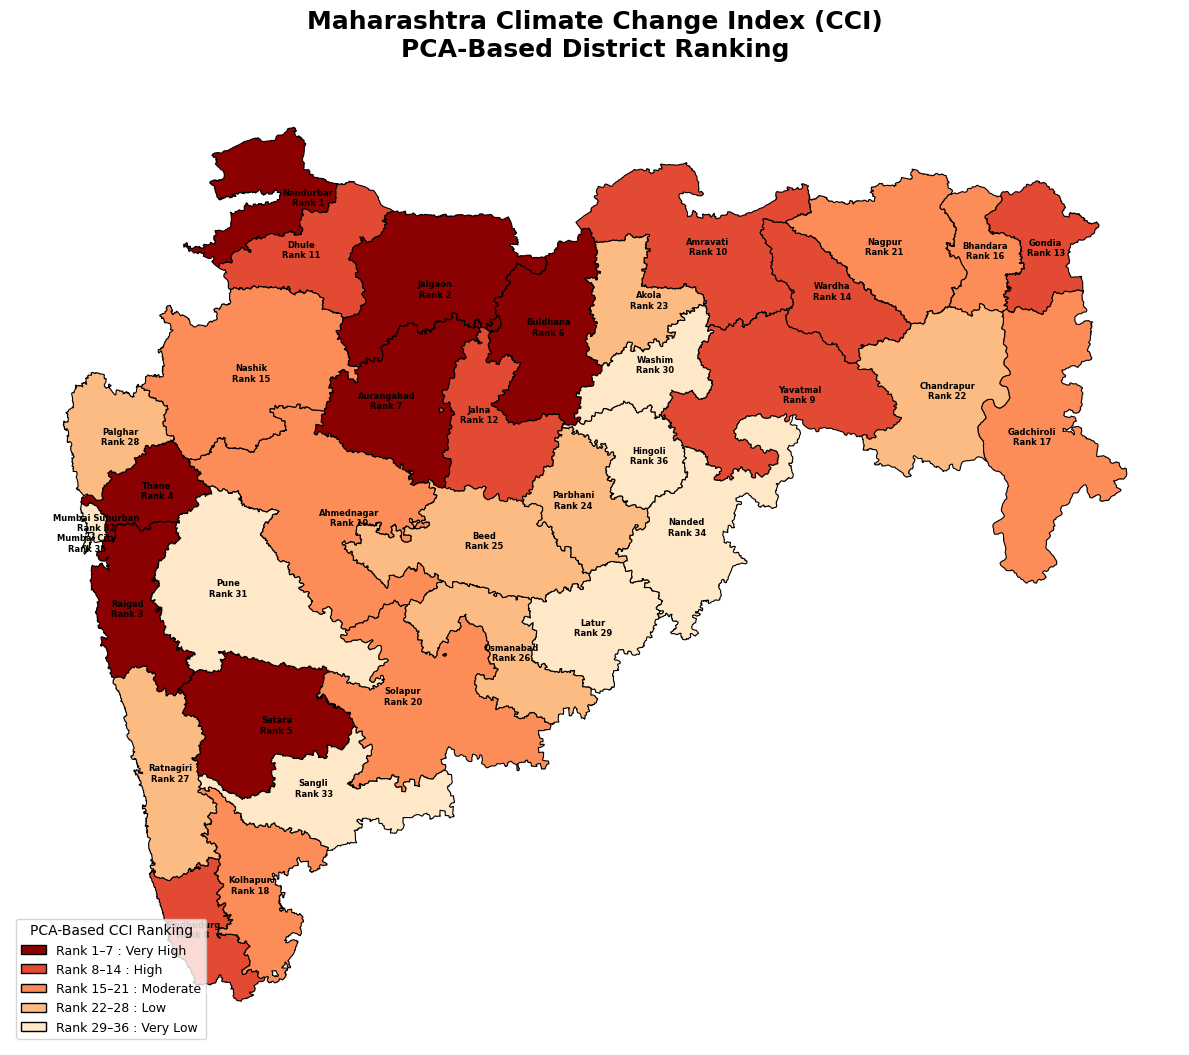


FINAL MAP CREATED SUCCESSFULLY!
CCI districts       : 36
Map districts       : 36
Matched districts   : 36
Unmatched districts : 0

Highest CCI:
Nandurbar → 40.9863

Lowest CCI:
Hingoli → 11.3134

Final PNG file:
Maharashtra_PCA_CCI_Final_36_District_Ranking_Map.png

DONE


In [ ]:
# ============================================================
# MAHARASHTRA CLIMATE CHANGE INDEX
# PCA-BASED FINAL DISTRICT RANKING MAP
# 36 DISTRICTS
# AUTOMATIC GEOJSON DOWNLOAD VERSION
# ============================================================


# ============================================================
# STEP 1: INSTALL PACKAGES
# ============================================================

!pip install geopandas matplotlib pandas requests openpyxl -q


# ============================================================
# STEP 2: IMPORT LIBRARIES
# ============================================================

import os
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


# ============================================================
# STEP 3: DOWNLOAD MAHARASHTRA 36-DISTRICT GEOJSON
# ============================================================

map_file = "Maharashtra_36_Districts.geojson"

url = "https://gist.githubusercontent.com/saketkc/7c1ce9d993773ced9974f6c57730b7df/raw/Maharashtra.geojson"

print("Downloading Maharashtra district map...")

response = requests.get(url, timeout=60)

print("Status code:", response.status_code)
print("Downloaded file size:", len(response.content), "bytes")

if response.status_code != 200:

    raise ValueError(
        "Could not download the Maharashtra GeoJSON."
    )

with open(map_file, "wb") as f:
    f.write(response.content)

print("GeoJSON downloaded successfully.")


# ============================================================
# STEP 4: READ GEOJSON
# ============================================================

maha = gpd.read_file(map_file)

print("\n==========================================")
print("MAP LOADED")
print("==========================================")

print("Number of map records:", len(maha))

print("\nMap columns:")
print(maha.columns.tolist())


# ============================================================
# STEP 5: CHECK DISTRICT COLUMN
# ============================================================

if "district_name" in maha.columns:

    district_column = "district_name"

elif "District" in maha.columns:

    district_column = "District"

elif "dtname" in maha.columns:

    district_column = "dtname"

else:

    raise ValueError(
        "District name column was not found."
    )


print("\nDistrict column:", district_column)


# Clean district names
maha[district_column] = (
    maha[district_column]
    .astype(str)
    .str.strip()
)


# ============================================================
# STEP 6: SHOW MAP DISTRICTS
# ============================================================

print("\n==========================================")
print("DISTRICTS IN MAP")
print("==========================================")

for district in sorted(
    maha[district_column].unique()
):

    print(district)


# ============================================================
# STEP 7: CREATE FINAL CCI DATA
# ============================================================

ranking_data = {

    "Rank": [
        1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
        11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
        21, 22, 23, 24, 25, 26, 27, 28, 29, 30,
        31, 32, 33, 34, 35, 36
    ],

    "District": [
        "Nandurbar",
        "Jalgaon",
        "Raigad",
        "Thane",
        "Satara",
        "Buldhana",
        "Aurangabad",
        "Sindhudurg",
        "Yavatmal",
        "Amravati",
        "Dhule",
        "Jalna",
        "Gondia",
        "Wardha",
        "Nashik",
        "Bhandara",
        "Gadchiroli",
        "Kolhapur",
        "Ahmednagar",
        "Solapur",
        "Nagpur",
        "Chandrapur",
        "Akola",
        "Parbhani",
        "Beed",
        "Osmanabad",
        "Ratnagiri",
        "Palghar",
        "Latur",
        "Washim",
        "Pune",
        "Mumbai Suburban",
        "Sangli",
        "Nanded",
        "Mumbai City",
        "Hingoli"
    ],

    "PCA_CCI": [
        40.9863,
        36.1641,
        29.4791,
        27.7496,
        27.6309,
        27.3127,
        27.2419,
        25.9139,
        25.7124,
        25.3796,
        21.3894,
        20.1119,
        19.8775,
        18.8630,
        17.8968,
        17.5891,
        17.5719,
        17.4281,
        17.0893,
        16.7034,
        16.3648,
        15.1309,
        15.0961,
        14.8974,
        14.5022,
        14.3497,
        14.3341,
        13.8126,
        13.5347,
        13.2186,
        12.9804,
        12.3870,
        12.0344,
        11.8361,
        11.7835,
        11.3134
    ]
}


cci_df = pd.DataFrame(ranking_data)


print("\n==========================================")
print("CCI DATA CREATED")
print("==========================================")

print("CCI districts:", len(cci_df))


# ============================================================
# STEP 8: CORRECT ONLY THE DIFFERENCE
# ============================================================

# Current map:
# Mumbai
# Mumbai Suburban
#
# CCI:
# Mumbai City
# Mumbai Suburban
#
# Therefore:
# Mumbai City -> Mumbai

name_corrections = {
    "Mumbai City": "Mumbai"
}

cci_df["Map_District"] = (
    cci_df["District"]
    .replace(name_corrections)
)


# ============================================================
# STEP 9: MERGE CCI DATA WITH MAP
# ============================================================

map_data = maha.merge(
    cci_df,
    left_on=district_column,
    right_on="Map_District",
    how="left"
)


# ============================================================
# STEP 10: CHECK MATCHING
# ============================================================

matched = (
    map_data["Rank"]
    .notna()
    .sum()
)

unmatched = (
    map_data.loc[
        map_data["Rank"].isna(),
        district_column
    ]
    .tolist()
)


print("\n==========================================")
print("FINAL DISTRICT MATCHING CHECK")
print("==========================================")

print("CCI districts       :", len(cci_df))
print("Map districts       :", len(maha))
print("Matched districts   :", matched)
print("Unmatched districts :", unmatched)


# ============================================================
# STEP 11: STOP IF MATCHING IS NOT 36/36
# ============================================================

if matched != 36:

    raise ValueError(
        "District matching failed.\n"
        f"Matched: {matched}\n"
        f"Unmatched: {unmatched}"
    )


print("\nSUCCESS!")
print("All 36 districts matched correctly.")


# ============================================================
# STEP 12: CREATE RANK CATEGORIES
# ============================================================

def rank_category(rank):

    if rank <= 7:
        return "Very High"

    elif rank <= 14:
        return "High"

    elif rank <= 21:
        return "Moderate"

    elif rank <= 28:
        return "Low"

    else:
        return "Very Low"


map_data["Category"] = (
    map_data["Rank"]
    .apply(rank_category)
)


# ============================================================
# STEP 13: DEFINE COLORS
# ============================================================

colors = {

    "Very High": "#8B0000",

    "High": "#E34A33",

    "Moderate": "#FC8D59",

    "Low": "#FDBB84",

    "Very Low": "#FEE8C8"
}


# ============================================================
# STEP 14: CREATE MAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 14)
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")


# ============================================================
# STEP 15: DRAW DISTRICTS
# ============================================================

for category in [
    "Very High",
    "High",
    "Moderate",
    "Low",
    "Very Low"
]:

    subset = map_data[
        map_data["Category"] == category
    ]

    subset.plot(
        ax=ax,
        color=colors[category],
        edgecolor="black",
        linewidth=0.8
    )


# ============================================================
# STEP 16: ADD DISTRICT NAME + RANK
# ============================================================

for _, row in map_data.iterrows():

    point = row.geometry.representative_point()

    label = (
        f"{row['District']}\n"
        f"Rank {int(row['Rank'])}"
    )

    ax.annotate(
        label,
        xy=(point.x, point.y),
        ha="center",
        va="center",
        fontsize=6,
        fontweight="bold",
        color="black"
    )


# ============================================================
# STEP 17: TITLE
# ============================================================

ax.set_title(
    "Maharashtra Climate Change Index (CCI)\n"
    "PCA-Based District Ranking",
    fontsize=18,
    fontweight="bold",
    pad=20
)


# ============================================================
# STEP 18: LEGEND
# ============================================================

legend_elements = [

    Patch(
        facecolor=colors["Very High"],
        edgecolor="black",
        label="Rank 1–7 : Very High"
    ),

    Patch(
        facecolor=colors["High"],
        edgecolor="black",
        label="Rank 8–14 : High"
    ),

    Patch(
        facecolor=colors["Moderate"],
        edgecolor="black",
        label="Rank 15–21 : Moderate"
    ),

    Patch(
        facecolor=colors["Low"],
        edgecolor="black",
        label="Rank 22–28 : Low"
    ),

    Patch(
        facecolor=colors["Very Low"],
        edgecolor="black",
        label="Rank 29–36 : Very Low"
    )
]


ax.legend(
    handles=legend_elements,
    title="PCA-Based CCI Ranking",
    loc="lower left",
    fontsize=9,
    title_fontsize=10,
    frameon=True
)


# ============================================================
# STEP 19: REMOVE AXES
# ============================================================

ax.axis("off")

plt.tight_layout()


# ============================================================
# STEP 20: SAVE FINAL MAP
# ============================================================

filename = (
    "Maharashtra_PCA_CCI_Final_36_District_Ranking_Map.png"
)

plt.savefig(
    filename,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)


# ============================================================
# STEP 21: DISPLAY MAP
# ============================================================

plt.show()


# ============================================================
# STEP 22: FINAL RESULT
# ============================================================

print("\n==============================================")
print("FINAL MAP CREATED SUCCESSFULLY!")
print("==============================================")

print("CCI districts       :", len(cci_df))
print("Map districts       :", len(maha))
print("Matched districts   :", matched)
print("Unmatched districts :", len(unmatched))

print("\nHighest CCI:")
highest = cci_df.loc[
    cci_df["PCA_CCI"].idxmax()
]

print(
    highest["District"],
    "→",
    highest["PCA_CCI"]
)

print("\nLowest CCI:")
lowest = cci_df.loc[
    cci_df["PCA_CCI"].idxmin()
]

print(
    lowest["District"],
    "→",
    lowest["PCA_CCI"]
)

print("\nFinal PNG file:")
print(filename)

print("\n==============================================")
print("DONE")
print("==============================================")